## The below packages are imported in the allcov environment

In [1]:
import thecov.geometry
import thecov.covariance
import thecov.base

# Libraries to handle basic cosmology and catalog manipulations
from mpytools import Catalog
import mockfactory.utils
import cosmoprimo
import numpy as np
import fitsio

from scipy.interpolate import interp1d
from pypower import PowerSpectrumMultipoles
import matplotlib.pyplot as plt

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
from matplotlib.colors import SymLogNorm
from matplotlib.colors import LogNorm

## The below packages are imported in the lens_equal_source environment

In [1]:
import os
import camb
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from colossus.cosmology import cosmology
from colossus.lss import mass_function, bias, peaks
from colossus.halo import mass_defs, concentration

### The galaxy clustering covariance matrix

In [3]:
#cov_matrix_2k = np.load('/pscratch/sd/l/lgong/pv_cov/LRG_NGC_clustering_DESIY1_P0_P2_Gaussian_cov_with_shotshoise.npy')
cov_matrix_gg = np.load('/pscratch/sd/l/lgong/pv_cov/LRG_NGC_clustering_DESIY1_P0_P2_P4_Gaussian_wo_SN_mc_kmodes_5e3.npy')
cov_matrix_vv = np.load('/pscratch/sd/l/lgong/pv_cov/BGS_DESIY1_P0_P2_P4_Gaussian_cov_wo_shotshoise_analytic_pv.npy')

In [14]:
print(cov_matrix_gg.shape)
print(cov_matrix_vv.shape)

(174, 174)
(82, 82)


In [5]:
# Define fiducial cosmology used in calculations
cosmo = cosmoprimo.fiducial.DESI()

# Load random catalog
randoms = Catalog.read("/pscratch/sd/l/lgong/pv_cov/LRG_NGC_0_clustering_cut_z0.4-0.6.ran.fits")

# Any catalog filtering/manipulations should go here
# The characteristic amplitude of the power spectrum
P0_characteristic = 1e4
# Whether RA and Dec are in degrees.
degree = True
# The Nyquist wavelength of the window FFTs should be at least as large as the largest k-bin used in covariance calculations.
kmax_window = 0.04
# Multiply the box size inferred from the catalog by this factor to get the box size used in window FFTs.
# Larger boxpad yields smaller k-fundamental.
boxpad = 2.0
# The ratio of the number of galaxies to the number of randoms. Should be used in covariance calculations to properly account
# for shot noise.
alpha = 0.15613865483217484
# Maixmum number of samples used in the Monte Carlo integration of the trispectrum covariance. Should be set to a large number for
# accurate results, but can be reduced for faster tests.
kmodes_sampled = 5000

# Should define FKP weights column with this name
# randoms["WEIGHT_FKP"] = 1.0 / (1.0 + P0_characteristic * randoms["NZ"])  # type: ignore  # FKP weights are optional

# Convert sky coordinates to cartesian using fiducial cosmology
randoms["POSITION"] = mockfactory.utils.sky_to_cartesian(
    cosmo.comoving_radial_distance(randoms["Z"]),
    randoms["RA"],
    randoms["DEC"],
    degree=degree,
)

# Create geometry object to be used in covariance calculation
geometry = thecov.geometry.SurveyGeometry(
    randoms,
    kmax_window=kmax_window,  # Nyquist wavelength of window FFTs
    boxpad=boxpad,  # multiplies the box size inferred from catalog
    alpha=alpha,  # N_galaxies / N_randoms
    kmodes_sampled=kmodes_sampled,  # max N samples used in integration
)

kmin = 0.01
kmax = 0.30
dk = 0.005

gaussian = thecov.covariance.GaussianCovariance(geometry)
gaussian.set_kbins(kmin, kmax, dk)

NZ column not found in randoms. Estimating it with RedshiftDensityInterpolator.


In [6]:
print(gaussian.kmid.shape)
print(gaussian.kbins)

(58,)
58


In [5]:
n_size = cov_matrix_gg.shape[0]

# ---------------------------------------------------------
# Method 2: Check the Matrix Rank
# ---------------------------------------------------------
# A matrix is degenerate if its rank is less than its dimensions.
rank = np.linalg.matrix_rank(cov_matrix_gg)
print(f"Matrix Rank: {rank} (Expected full rank: {n_size})")
if rank < n_size:
    print("-> Matrix is degenerate (rank-deficient).")

# ---------------------------------------------------------
# Method 3: Check the Eigenvalues
# ---------------------------------------------------------
# Since a covariance matrix is symmetric, we can use eigvalsh (which is faster 
# and more stable than eigvals). If any eigenvalue is <= 0 (within machine precision), 
# it is degenerate.
eigenvalues = np.linalg.eigvals(cov_matrix_gg)
min_eigenvalue = np.min(eigenvalues)
max_eigenvalue = np.max(eigenvalues)
print(f"Minimum Eigenvalue: {min_eigenvalue:.2e}")
print(f"Maximum Eigenvalue: {max_eigenvalue:.2e}")
if min_eigenvalue <= 1e-12:  # Using a small tolerance for floating-point math
    print("-> Matrix is degenerate (contains zero or negative eigenvalues).")

Matrix Rank: 174 (Expected full rank: 174)
Minimum Eigenvalue: -3.60e+04
Maximum Eigenvalue: 3.59e+08
-> Matrix is degenerate (contains zero or negative eigenvalues).


In [4]:
n_size = cov_matrix_vv.shape[0]

# ---------------------------------------------------------
# Method 2: Check the Matrix Rank
# ---------------------------------------------------------
# A matrix is degenerate if its rank is less than its dimensions.
rank = np.linalg.matrix_rank(cov_matrix_vv)
print(f"Matrix Rank: {rank} (Expected full rank: {n_size})")
if rank < n_size:
    print("-> Matrix is degenerate (rank-deficient).")

# ---------------------------------------------------------
# Method 3: Check the Eigenvalues
# ---------------------------------------------------------
# Since a covariance matrix is symmetric, we can use eigvalsh (which is faster 
# and more stable than eigvals). If any eigenvalue is <= 0 (within machine precision), 
# it is degenerate.
eigenvalues = np.linalg.eigvals(cov_matrix_vv)
min_eigenvalue = np.min(eigenvalues)
max_eigenvalue = np.max(eigenvalues)
print(f"Minimum Eigenvalue: {min_eigenvalue:.2e}")
print(f"Maximum Eigenvalue: {max_eigenvalue:.2e}")
if min_eigenvalue <= 1e-12:  # Using a small tolerance for floating-point math
    print("-> Matrix is degenerate (contains zero or negative eigenvalues).")

Matrix Rank: 246 (Expected full rank: 246)
Minimum Eigenvalue: -7.21e+19+0.00e+00j
Maximum Eigenvalue: 1.15e+23+0.00e+00j
-> Matrix is degenerate (contains zero or negative eigenvalues).


In [6]:
diag = np.diagonal(cov_matrix_gg)
has_negative = np.any(diag < 0)
print("The diagonal entries have negative values: ", has_negative)
total_negatives = np.sum(diag < 0)
print("How many negative entries the diagonal elements have: ", total_negatives)
is_symmetric = np.array_equal(cov_matrix_gg, cov_matrix_gg.T)
print("Is the matrix strictly symmetric: ", is_symmetric)
max_asymmetry = np.max(cov_matrix_gg - cov_matrix_gg.T)
print("The maximum asymmetric difference value is: ", max_asymmetry)
max_asymmetry_entry = np.where((cov_matrix_gg - cov_matrix_gg.T) == max_asymmetry)
print("The maximum asymmetric difference value is at: ", max_asymmetry_entry)
print("The matrix value at the maximum asymmetry is: ", cov_matrix_gg[max_asymmetry_entry])
print("The asymmetry at similar locations in Quadrupole is: ", (cov_matrix_gg - cov_matrix_gg.T)[59,58]/cov_matrix_gg[59,58])
print("The asymmetry at similar locations in Monopole is: ", (cov_matrix_gg - cov_matrix_gg.T)[1,0]/cov_matrix_gg[1,0])

The diagonal entries have negative values:  False
How many negative entries the diagonal elements have:  0
Is the matrix strictly symmetric:  False
The maximum asymmetric difference value is:  15068185.565642446
The maximum asymmetric difference value is at:  (array([117]), array([116]))
The matrix value at the maximum asymmetry is:  [1.21737633e+08]
The asymmetry at similar locations in Quadrupole is:  0.03145950349926873
The asymmetry at similar locations in Monopole is:  -0.002549298634783461


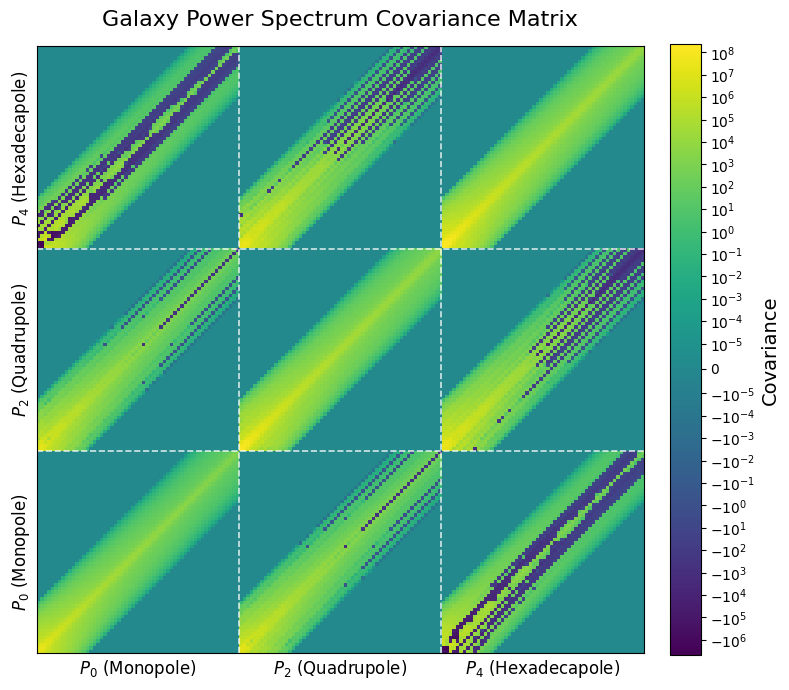

In [13]:
n_bins = 58

fig, ax = plt.subplots(figsize=(8, 8))

# Plot the raw covariance matrix
# Note: If the diagonal completely washes out the rest of the plot, 
# uncomment the 'norm' argument below to use a logarithmic color scale.
cax = ax.imshow(
    cov_matrix_gg, 
    cmap='viridis', 
    origin='lower',
    norm=SymLogNorm(linthresh=1e-5, vmin=cov_matrix_gg.min(), vmax=cov_matrix_gg.max())
)

# Add the colorbar showing the actual covariance values
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Covariance', fontsize=14)

# Draw separator lines between the multipole blocks
# (Using white or a light color so it stands out against the dark background of viridis)
for i in [1, 2]:
    ax.axhline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)
    ax.axvline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)

# Set custom ticks and labels at the center of each block
tick_positions = [n_bins / 2 - 0.5, 
                  n_bins + n_bins / 2 - 0.5, 
                  2 * n_bins + n_bins / 2 - 0.5]
tick_labels = [r'$P_0$ (Monopole)', r'$P_2$ (Quadrupole)', r'$P_4$ (Hexadecapole)']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=12, rotation=90, va='center')

# Remove the standard minor ticks
ax.tick_params(axis='both', which='both', length=0)

plt.title('Galaxy Power Spectrum Covariance Matrix', fontsize=16, pad=15)
plt.tight_layout()

# Show the plot
plt.show()

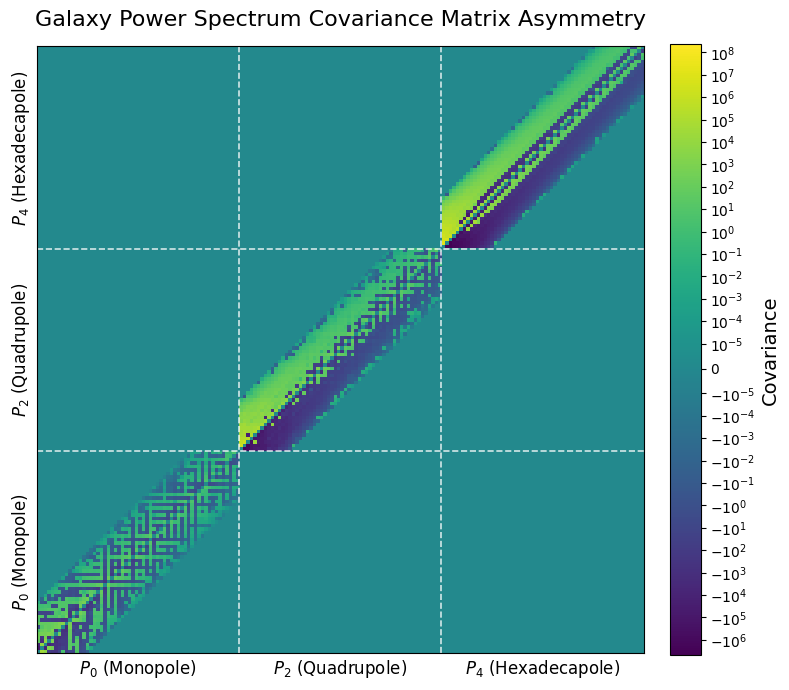

In [19]:
n_bins = 58

fig, ax = plt.subplots(figsize=(8, 8))

# Plot the raw covariance matrix
# Note: If the diagonal completely washes out the rest of the plot, 
# uncomment the 'norm' argument below to use a logarithmic color scale.
cax = ax.imshow(
    cov_matrix_gg - cov_matrix_gg.T, 
    cmap='viridis', 
    origin='lower',
    norm=SymLogNorm(linthresh=1e-5, vmin=cov_matrix_gg.min(), vmax=cov_matrix_gg.max())
)

# Add the colorbar showing the actual covariance values
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Covariance', fontsize=14)

# Draw separator lines between the multipole blocks
# (Using white or a light color so it stands out against the dark background of viridis)
for i in [1, 2]:
    ax.axhline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)
    ax.axvline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)

# Set custom ticks and labels at the center of each block
tick_positions = [n_bins / 2 - 0.5, 
                  n_bins + n_bins / 2 - 0.5, 
                  2 * n_bins + n_bins / 2 - 0.5]
tick_labels = [r'$P_0$ (Monopole)', r'$P_2$ (Quadrupole)', r'$P_4$ (Hexadecapole)']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=12, rotation=90, va='center')

# Remove the standard minor ticks
ax.tick_params(axis='both', which='both', length=0)

plt.title('Galaxy Power Spectrum Covariance Matrix Asymmetry', fontsize=16, pad=15)
plt.tight_layout()

# Show the plot
plt.show()

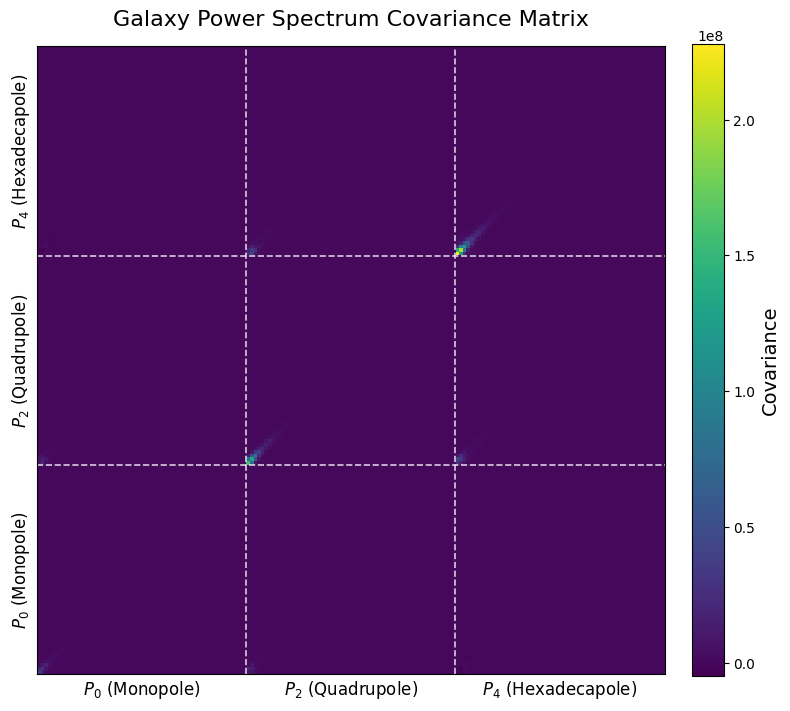

In [14]:
n_bins = 58

fig, ax = plt.subplots(figsize=(8, 8))

# Plot the raw covariance matrix
# Note: If the diagonal completely washes out the rest of the plot, 
# uncomment the 'norm' argument below to use a logarithmic color scale.
cax = ax.imshow(
    cov_matrix_gg, 
    cmap='viridis', 
    origin='lower',
    #norm=SymLogNorm(linthresh=1e-5, vmin=cov_matrix_gg.min(), vmax=cov_matrix_gg.max())
)

# Add the colorbar showing the actual covariance values
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Covariance', fontsize=14)

# Draw separator lines between the multipole blocks
# (Using white or a light color so it stands out against the dark background of viridis)
for i in [1, 2]:
    ax.axhline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)
    ax.axvline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)

# Set custom ticks and labels at the center of each block
tick_positions = [n_bins / 2 - 0.5, 
                  n_bins + n_bins / 2 - 0.5, 
                  2 * n_bins + n_bins / 2 - 0.5]
tick_labels = [r'$P_0$ (Monopole)', r'$P_2$ (Quadrupole)', r'$P_4$ (Hexadecapole)']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=12, rotation=90, va='center')

# Remove the standard minor ticks
ax.tick_params(axis='both', which='both', length=0)

plt.title('Galaxy Power Spectrum Covariance Matrix', fontsize=16, pad=15)
plt.tight_layout()

# Show the plot
plt.show()

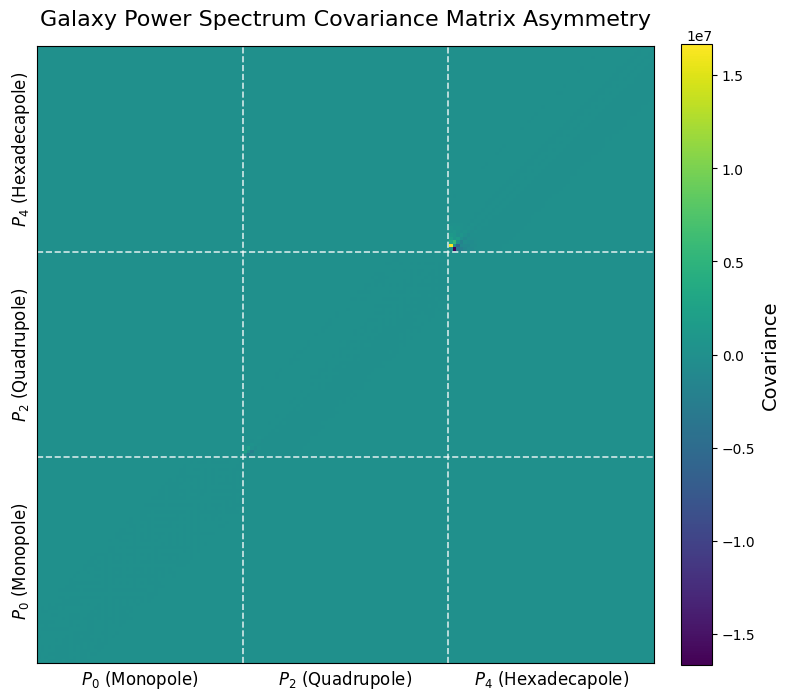

In [18]:
n_bins = 58

fig, ax = plt.subplots(figsize=(8, 8))

# Plot the raw covariance matrix
# Note: If the diagonal completely washes out the rest of the plot, 
# uncomment the 'norm' argument below to use a logarithmic color scale.
cax = ax.imshow(
    cov_matrix_gg - cov_matrix_gg.T, 
    cmap='viridis', 
    origin='lower',
    #norm=SymLogNorm(linthresh=1e-5, vmin=cov_matrix_gg.min(), vmax=cov_matrix_gg.max())
)

# Add the colorbar showing the actual covariance values
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Covariance', fontsize=14)

# Draw separator lines between the multipole blocks
# (Using white or a light color so it stands out against the dark background of viridis)
for i in [1, 2]:
    ax.axhline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)
    ax.axvline(i * n_bins - 0.5, color='white', linestyle='--', lw=1.2, alpha=0.8)

# Set custom ticks and labels at the center of each block
tick_positions = [n_bins / 2 - 0.5, 
                  n_bins + n_bins / 2 - 0.5, 
                  2 * n_bins + n_bins / 2 - 0.5]
tick_labels = [r'$P_0$ (Monopole)', r'$P_2$ (Quadrupole)', r'$P_4$ (Hexadecapole)']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=12, rotation=90, va='center')

# Remove the standard minor ticks
ax.tick_params(axis='both', which='both', length=0)

plt.title('Galaxy Power Spectrum Covariance Matrix Asymmetry', fontsize=16, pad=15)
plt.tight_layout()

# Show the plot
plt.show()

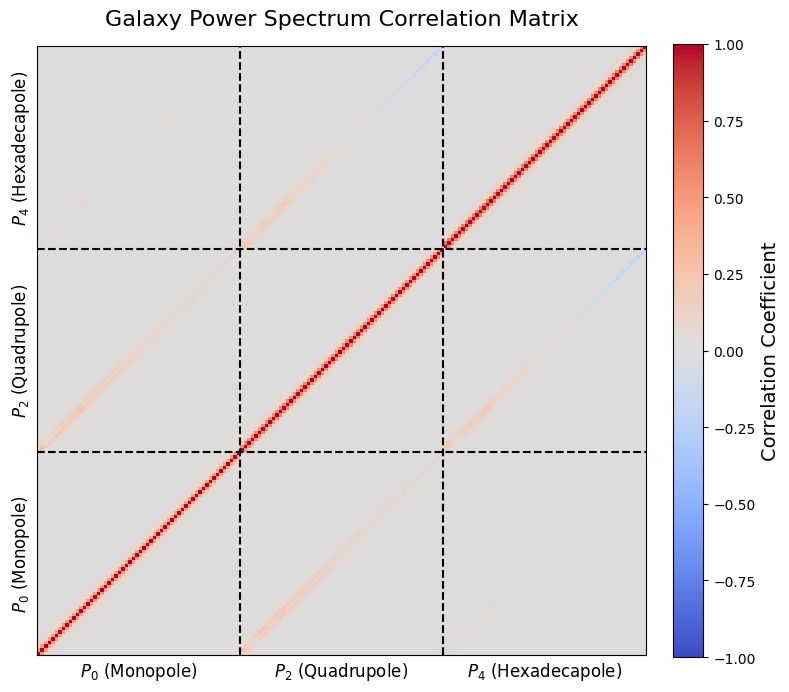

In [15]:
n_bins = 58

# 1. Convert Covariance to Correlation Matrix
# cor_ij = cov_ij / sqrt(cov_ii * cov_jj)
std_dev = np.sqrt(np.diag(cov_matrix_gg))
cor_matrix = cov_matrix_gg / np.outer(std_dev, std_dev)

# 2. Set up the plot
fig, ax = plt.subplots(figsize=(8, 8))

# Plot the correlation matrix
# Using 'coolwarm' cmap: Red=Positive correlation, Blue=Negative, White=Zero
cax = ax.imshow(cor_matrix, cmap='coolwarm', vmin=-1, vmax=1, origin='lower')

# Add a colorbar
cbar = fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Correlation Coefficient', fontsize=14)

# 3. Draw separator lines between the multipole blocks
# We subtract 0.5 so the line falls exactly between the pixels
for i in [1, 2]:
    ax.axhline(i * n_bins - 0.5, color='black', linestyle='--', lw=1.5)
    ax.axvline(i * n_bins - 0.5, color='black', linestyle='--', lw=1.5)

# 4. Set custom ticks and labels at the center of each block
# Centers are at ~29, 87, and 145
tick_positions = [n_bins / 2 - 0.5, 
                  n_bins + n_bins / 2 - 0.5, 
                  2 * n_bins + n_bins / 2 - 0.5]
tick_labels = [r'$P_0$ (Monopole)', r'$P_2$ (Quadrupole)', r'$P_4$ (Hexadecapole)']

ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(tick_positions)
ax.set_yticklabels(tick_labels, fontsize=12, rotation=90, va='center')

# Remove the standard minor ticks
ax.tick_params(axis='both', which='both', length=0)

plt.title('Galaxy Power Spectrum Correlation Matrix', fontsize=16, pad=15)
plt.tight_layout()

# Show the plot
plt.show()

In [7]:
cov_matrix_gg_diag = np.diagonal(cov_matrix_gg)
k_cov = gaussian.kmid
print(cov_matrix_gg_diag.shape)

(174,)


In [8]:
pk = PowerSpectrumMultipoles.load('/global/cfs/cdirs/desi/survey/catalogs/Y1/LSS/iron/LSScats/v1.5/unblinded/desipipe/baseline_2pt/pk/pkpoles_LRG_NGC_z0.4-0.6.npy')
kmode = pk.k
P0 = pk(ell=0)
P2 = pk(ell=2)
P4 = pk(ell=4)

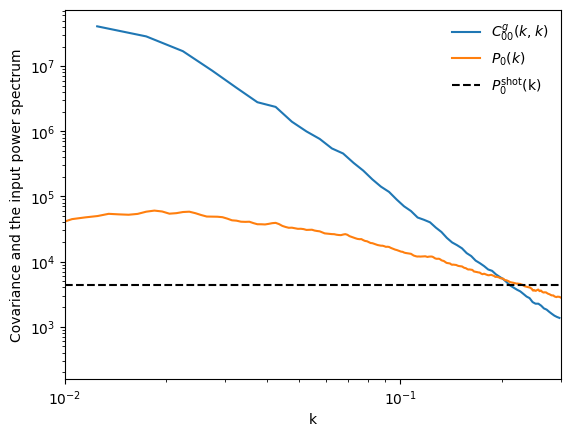

In [16]:
plt.figure()
plt.plot(k_cov, cov_matrix_gg_diag[:58], label=r'$C^g_{00}(k,k)$')
plt.plot(kmode, P0, label=r'$P_0(k)$')
plt.hlines(4380.5, xmin=0.01, xmax=0.3, label=r'$P_0^{\rm shot}$(k)', color='black', linestyle='--')
plt.xscale('log')
plt.yscale('log')
plt.xlim((0.01, 0.3))
plt.xlabel('k')
plt.ylabel('Covariance and the input power spectrum')
plt.legend(frameon=False)

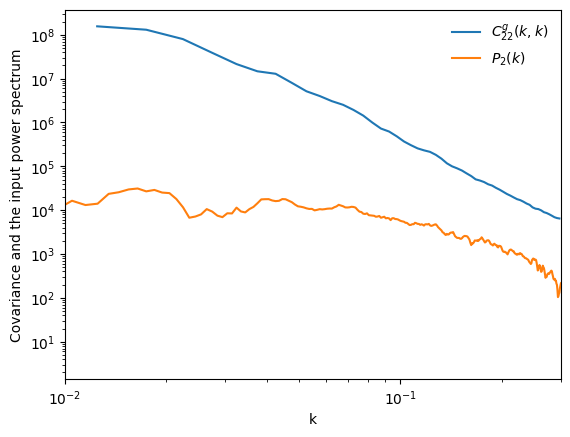

In [15]:
plt.figure()
plt.plot(k_cov, cov_matrix_gg_diag[58:116], label=r'$C^g_{22}(k,k)$')
plt.plot(kmode, P2, label=r'$P_2(k)$')
plt.xscale('log')
plt.yscale('log')
plt.xlim((0.01, 0.3))
plt.xlabel('k')
plt.ylabel('Covariance and the input power spectrum')
plt.legend(frameon=False)

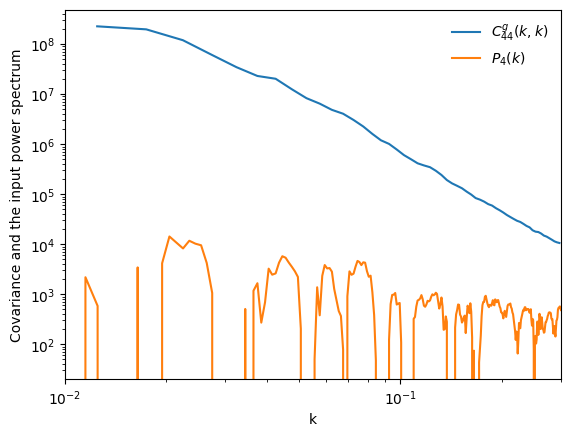

In [17]:
plt.figure()
plt.plot(k_cov, cov_matrix_gg_diag[116:174], label=r'$C^g_{44}(k,k)$')
plt.plot(kmode, P4, label=r'$P_4(k)$')
plt.xscale('log')
plt.yscale('log')
plt.xlim((0.01, 0.3))
plt.xlabel('k')
plt.ylabel('Covariance and the input power spectrum')
plt.legend(frameon=False)

In [42]:
data = Table.read("/pscratch/sd/l/lgong/pv_cov/LRG_NGC_clustering_cut_z0.4-0.6.dat.fits")
randoms = Table.read("/pscratch/sd/l/lgong/pv_cov/LRG_NGC_0_clustering_cut_z0.4-0.6.ran.fits")
#randoms = Table.read("/global/cfs/cdirs/desi/science/td/pv/mocks/FP_mocks/clusteringmocks/v0.5.2/FP_AbacusSummit_clustering_randoms20_v2.fits", format='fits')
print(data.colnames)
print(randoms.colnames)

['TARGETID', 'Z', 'NTILE', 'RA', 'DEC', 'PHOTSYS', 'FRAC_TLOBS_TILES', 'WEIGHT_ZFAIL', 'WEIGHT_SYS', 'WEIGHT', 'WEIGHT_COMP', 'NX', 'WEIGHT_FKP']
['TARGETID', 'RA', 'DEC', 'NTILE', 'PHOTSYS', 'FRAC_TLOBS_TILES', 'Z', 'WEIGHT', 'WEIGHT_SYS', 'WEIGHT_COMP', 'WEIGHT_ZFAIL', 'TARGETID_DATA', 'NX', 'WEIGHT_FKP']


In [56]:
print((randoms['WEIGHT_ZFAIL']*randoms['WEIGHT_SYS']*randoms['WEIGHT_COMP'])[:10])
print(randoms['WEIGHT'][:10])
print(((randoms['WEIGHT_ZFAIL']*randoms['WEIGHT_SYS']*randoms['WEIGHT_COMP'])/randoms['WEIGHT'])[:10])

   WEIGHT_ZFAIL   
------------------
0.9958866238594055
0.9582869410514832
0.9822669625282288
1.9911494255065918
0.9274173857137455
2.0690059661865234
0.9983722567558289
1.0390183704352012
1.0119497776031494
1.9315037727355957
      WEIGHT      
------------------
0.5723547693124041
0.5507455245809615
0.5645272938422454
 1.144351016269138
0.5330042106594668
1.1890966342066824
0.5737833092776408
0.5971433951157724
0.5815865658193207
1.1100715380490842
   WEIGHT_ZFAIL   
------------------
1.7399813494274006
1.7399813494274008
1.7399813494274003
1.7399813494274006
1.7399813494274006
1.7399813494274006
1.7399813494274006
1.7399813494274006
1.7399813494274008
1.7399813494274008


/tmp/ipykernel_2108183/2504064026.py:3: RuntimeWarning: divide by zero encountered in divide
  print(((randoms['WEIGHT_ZFAIL']*randoms['WEIGHT_SYS']*randoms['WEIGHT_COMP'])/randoms['WEIGHT'])[:10])


In [3]:
randoms.rename_column("NPV", "NZ")

In [4]:
randoms.write('/pscratch/sd/l/lgong/pv_cov/updated_desiy1_random_catalog_abacus_mock.fits', format="fits", overwrite=True)

In [3]:
print(randoms['WEIGHT'])
print(randoms['WEIGHT_FKP'])

WEIGHT
------
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   ...
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
   1.0
Length = 1566620 rows
      WEIGHT_FKP     
---------------------
 0.002076419308084784
 0.002553139756351717
 0.002430296338220722
0.0021250542144922837
0.0028060519169121685
 0.004173319974299815
0.0018309702498563011
 0.003824006534431802
0.0019392153921835894
0.0019846399478336235
                  ...
0.0017535156259120247
0.0026535340772059364
   0.0038267667058298
 0.002106706617427868
0.0020672042510364187
0.0012958687507082585
0.0012719108427877918
 0.002972818636253781
0.0028746629589090885
0.0028775138172909063
Length = 1566620 rows


In [5]:
print(randoms['WEIGHT_FKP'].min())
print(randoms['WEIGHT_FKP'].max())

0.15458917268650868
0.2755830206776556


In [4]:
(randoms['WEIGHT'].data == 1).all()

np.True_

In [5]:
params = {
    'flat': True, 
    'H0': 67.32, 
    'Om0': 0.3, 
    'Ob0': 0.04, 
    'As': 2.1e-9, 
    'ns': 0.96605,
    'de_model': 'lambda'
}

# 1. Convert fractional densities to physical densities
h = params['H0'] / 100.0
ombh2 = params['Ob0'] * h**2
omch2 = (params['Om0'] - params['Ob0']) * h**2 

# 2. Initialize CAMB parameters
pars = camb.CAMBparams()

# 3. Set the background cosmology
pars.set_cosmology(H0=params['H0'], ombh2=ombh2, omch2=omch2)

# 4. Set the primordial power spectrum
pars.InitPower.set_params(As=params['As'], ns=params['ns'])

# ---------------------------------------------------------
# THE FIX: Tell CAMB to compute the matter power spectrum 
# (and transfer functions) at z=0 up to a given kmax
# ---------------------------------------------------------
pars.set_matter_power(redshifts=[0.], kmax=5.0)

# 5. Compute the results and extract sigma8 at z=0
results = camb.get_results(pars)
sigma8_calculated = results.get_sigma8()[0]

print(f"Input As: {params['As']}")
print(f"Derived sigma8 (z=0): {sigma8_calculated:.4f}")

Input As: 2.1e-09
Derived sigma8 (z=0): 0.8304


In [6]:
S8 = sigma8_calculated*np.sqrt(params['Om0']/0.3)
print(S8)

0.8303587530469446


In [7]:
params = {
    'flat': True, 
    'H0': 67.36, 
    'Om0': 0.3138, 
    'Ob0': 0.0493, 
    'sigma8': 0.807952, 
    'ns': 0.9649,
    'de_model': 'lambda'
}
cosmo = cosmology.setCosmology('abacus_cosmo000', **params)

In [8]:
z_min = 0.0
z_max = 0.1
area_sqdeg = 14000

#Calculate solid angle in steradians
omega_sr = area_sqdeg * (np.pi / 180)**2

#Calculate comoving distances in Mpc/h
Dc_min = cosmo.comovingDistance(z_min=0.0, z_max=z_min)
Dc_max = cosmo.comovingDistance(z_min=0.0, z_max=z_max)

#Calculate comoving volume
volume = (omega_sr / 3) * (Dc_max**3 - Dc_min**3)

print(f"Sky Coverage: {omega_sr:.3f} steradians")
print(f"Min Comoving Distance (z={z_min}): {Dc_min:.2f} Mpc/h")
print(f"Max Comoving Distance (z={z_max}): {Dc_max:.2f} Mpc/h")
print(f"Comoving Volume: {volume:.2e} (Mpc/h)^3")

Sky Coverage: 4.265 steradians
Min Comoving Distance (z=0.0): 0.00 Mpc/h
Max Comoving Distance (z=0.1): 292.61 Mpc/h
Comoving Volume: 3.56e+07 (Mpc/h)^3


In [9]:
nbar = 98292/volume
print(nbar)

0.0027597553081437727


In [10]:
fsky = 14000/41252.96
print(fsky)

0.33936958705508646


In [11]:
z_obs = randoms['Z']
D_M_array = cosmo.comovingDistance(z_min=0.0, z_max=z_obs)
H_array = cosmo.Hz(z_obs)
alpha = 1/np.log(10) * (1 + z_obs)/(D_M_array * H_array)

In [12]:
FKP_weight = 1/(randoms['LOGDIST_ERR']**2/alpha + alpha*randoms['NPV']/10**10)

In [13]:
print(FKP_weight)

     LOGDIST_ERR     
---------------------
 0.002076419308084784
 0.002553139756351717
 0.002430296338220722
0.0021250542144922837
0.0028060519169121685
 0.004173319974299815
0.0018309702498563011
 0.003824006534431802
0.0019392153921835894
0.0019846399478336235
                  ...
0.0017535156259120247
0.0026535340772059364
   0.0038267667058298
 0.002106706617427868
0.0020672042510364187
0.0012958687507082585
0.0012719108427877918
 0.002972818636253781
0.0028746629589090885
0.0028775138172909063
Length = 1566620 rows


In [15]:
randoms['WEIGHT_FKP'] = FKP_weight

In [20]:
output_dir = '/pscratch/sd/l/lgong/pv_cov/'
output_file = 'updated_desiy1_random_catalog_abacus_mock.fits'

# Combine them to make the full path
full_output_path = os.path.join(output_dir, output_file)

# PRO-TIP: Make sure the directory actually exists before saving!
# exist_ok=True means it won't crash if the folder is already there
os.makedirs(output_dir, exist_ok=True)

# Save it to the new directory
randoms.write(full_output_path, format='fits', overwrite=True)
print(f"Saved successfully to {full_output_path}")

Saved successfully to /pscratch/sd/l/lgong/pv_cov/updated_desiy1_random_catalog_abacus_mock.fits


In [8]:
nz = np.loadtxt("/pscratch/sd/l/lgong/pv_cov/LRG_NGC_nz.txt")

In [9]:
nz.shape

(70, 6)

In [3]:
print(randoms['RA'].shape)
print(data['RA'].shape)

(2220853,)
(346761,)


In [13]:
print(randoms['RA'].max())
print(randoms['NPV'][:10])

359.99982142798694
[0.00297532 0.00422582 0.00366525 0.0033634  0.00323404 0.00366525
 0.00086241 0.00323404 0.00349277 0.00245787]


In [7]:
print(randoms.columns)
print(data.columns)

<TableColumns names=('TARGETID','RA','DEC','NTILE','PHOTSYS','FRAC_TLOBS_TILES','Z','WEIGHT','WEIGHT_SYS','WEIGHT_COMP','WEIGHT_ZFAIL','TARGETID_DATA','NX','WEIGHT_FKP')>
<TableColumns names=('TARGETID','Z','NTILE','RA','DEC','PHOTSYS','FRAC_TLOBS_TILES','WEIGHT_ZFAIL','WEIGHT_SYS','WEIGHT','WEIGHT_COMP','NX','WEIGHT_FKP')>


In [4]:
alpha = 346761/2220853
print(alpha)

0.15613865483217484


In [27]:
infile = '/pscratch/sd/l/lgong/pv_cov/LRG_NGC_clustering.dat.fits'
outfile = '/pscratch/sd/l/lgong/pv_cov/LRG_NGC_clustering_cut_z0.4-0.6.dat.fits'

print("Reading data...")
# Read the data from the first extension (usually where DESI tables live)
# You can specify columns=['Z', 'RA', 'DEC', ...] if you don't want to load everything to save memory
data = fitsio.read(infile, ext=1)

print("Applying redshift cut...")
# Create a boolean mask for your redshift range
mask = (data['Z'] >= 0.4) & (data['Z'] <= 0.6)

# Apply the mask to filter the data
filtered_data = data[mask]

print(f"Keeping {len(filtered_data)} out of {len(data)} galaxies.")

print("Saving to new FITS file...")
# Write the filtered data to a new file (clobber=True overwrites if it already exists)
fitsio.write(outfile, filtered_data, clobber=True)
print("Done!")

Reading data...
Applying redshift cut...
Keeping 346761 out of 1476135 galaxies.
Saving to new FITS file...
Done!


In [5]:
pk = PowerSpectrumMultipoles.load('/global/cfs/cdirs/desi/survey/catalogs/Y1/LSS/iron/LSScats/v1.5/unblinded/desipipe/baseline_2pt/pk/pkpoles_LRG_NGC_z0.4-0.6.npy')

In [6]:
k = pk.k

# Extract your multipoles (automatically normalized, real-valued, and shot-noise corrected!)
P0 = pk(ell=0)
P2 = pk(ell=2)
P4 = pk(ell=4)

# You can even extract complex cross-poles or format it beautifully
print(f"Available multipoles: {pk.ells}")
print(f"Shot noise applied: {pk.shotnoise}")

Available multipoles: (0, 2, 4)
Shot noise applied: 4582.786621290802


/global/u1/l/lgong/allcov/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/global/u1/l/lgong/allcov/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


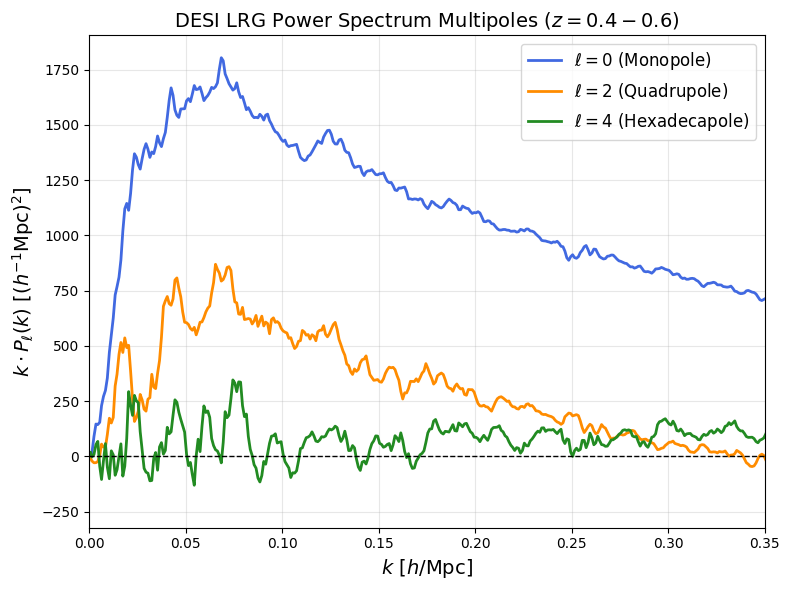

In [18]:
plt.figure(figsize=(8, 6))

# Plotting k * P(k) for each multipole
plt.plot(k, k * P0, label=r'$\ell=0$ (Monopole)', color='royalblue', lw=2)
plt.plot(k, k * P2, label=r'$\ell=2$ (Quadrupole)', color='darkorange', lw=2)
plt.plot(k, k * P4, label=r'$\ell=4$ (Hexadecapole)', color='forestgreen', lw=2)

# Add a horizontal zero-line for reference (useful for P2 and P4)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# Formatting the plot
plt.xlim(0, 0.35)  # Restricting to standard cosmological fitting ranges
plt.xlabel(r'$k \ [h/\mathrm{Mpc}]$', fontsize=14)
plt.ylabel(r'$k \cdot P_\ell(k) \ [(h^{-1}\mathrm{Mpc})^2]$', fontsize=14)
plt.title('DESI LRG Power Spectrum Multipoles ($z=0.4-0.6$)', fontsize=14)

plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()

In [9]:
pv = np.load('/pscratch/sd/l/lgong/pv_cov/pk_model_output.npz')
print(pv.files)

['pk_den', 'k_den', 'pk_mom', 'k_mom', 'pk_cross', 'k_cross']


In [5]:
k_mom = pv['k_mom']
pk_mom = pv['pk_mom']

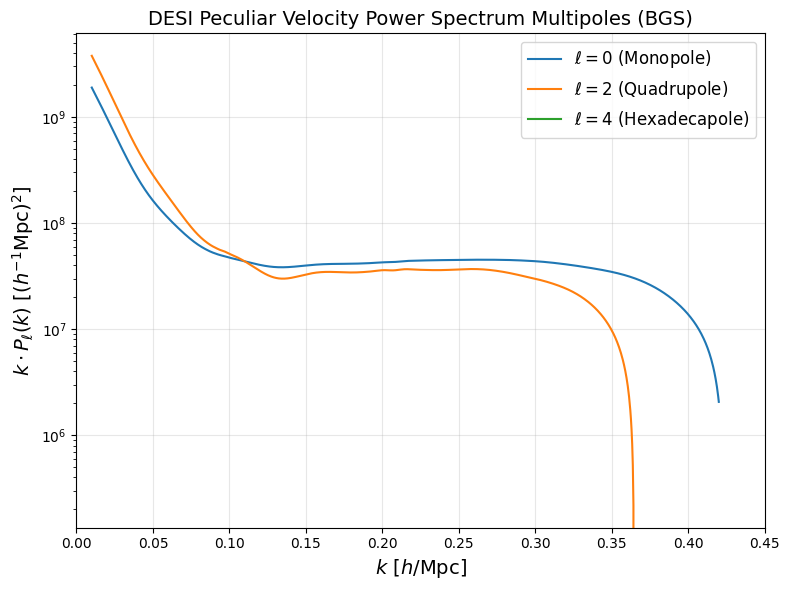

In [6]:
plt.figure(figsize=(8, 6))
plt.plot(k_mom[:1000], k_mom[:1000]*pk_mom[:1000], label=r'$\ell=0$'+' (Monopole)')
plt.plot(k_mom[1000:2000], k_mom[1000:2000]*pk_mom[1000:2000], label=r'$\ell=2$'+' (Quadrupole)')
plt.plot(k_mom[2000:3000], k_mom[2000:3000]*pk_mom[2000:3000], label=r'$\ell=4$'+' (Hexadecapole)')
# Add a horizontal zero-line for reference (useful for P2 and P4)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# Formatting the plot
plt.xlim(0, 0.45)  # Restricting to standard cosmological fitting ranges
plt.xlabel(r'$k \ [h/\mathrm{Mpc}]$', fontsize=14)
plt.ylabel(r'$k \cdot P_\ell(k) \ [(h^{-1}\mathrm{Mpc})^2]$', fontsize=14)
plt.title('DESI Peculiar Velocity Power Spectrum Multipoles (BGS)', fontsize=14)
#plt.xscale('log')
plt.yscale('log')

plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()

In [12]:
pv = np.load('/pscratch/sd/l/lgong/pv_cov/Pkmulti_mom.npy')
k_mom = pv[0,:1000]
pv0 = pv[1,:1000]
pv2 = pv[1, 1000:2000]
pv4 = pv[1, 2000:3000]

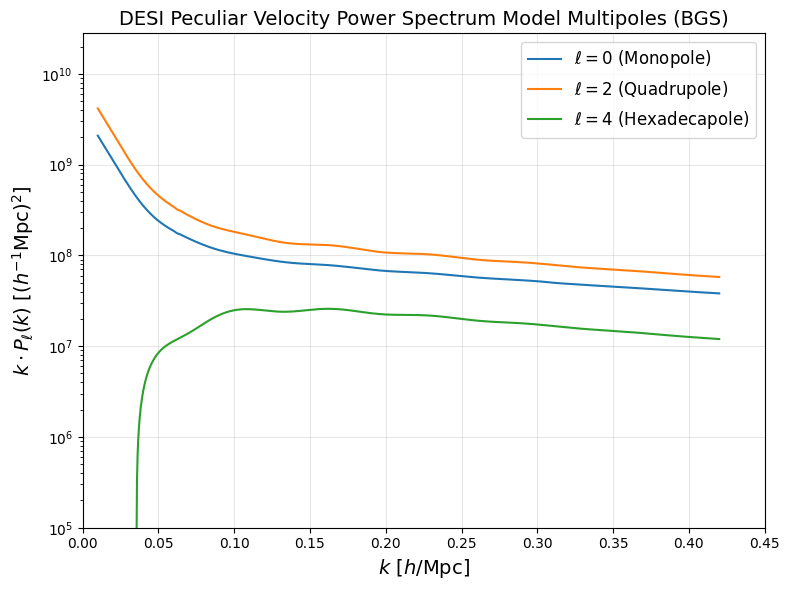

In [13]:
plt.figure(figsize=(8, 6))
plt.plot(k_mom, k_mom*pv0, label=r'$\ell=0$'+' (Monopole)')
plt.plot(k_mom, k_mom*pv2, label=r'$\ell=2$'+' (Quadrupole)')
plt.plot(k_mom, k_mom*pv4, label=r'$\ell=4$'+' (Hexadecapole)')
# Add a horizontal zero-line for reference (useful for P2 and P4)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# Formatting the plot
plt.xlim(0, 0.45)  # Restricting to standard cosmological fitting ranges
plt.xlabel(r'$k \ [h/\mathrm{Mpc}]$', fontsize=14)
plt.ylabel(r'$k \cdot P_\ell(k) \ [(h^{-1}\mathrm{Mpc})^2]$', fontsize=14)
plt.title('DESI Peculiar Velocity Power Spectrum Model Multipoles (BGS)', fontsize=14)
#plt.xscale('log')
plt.yscale('log')
plt.ylim(bottom=1e5)

plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()

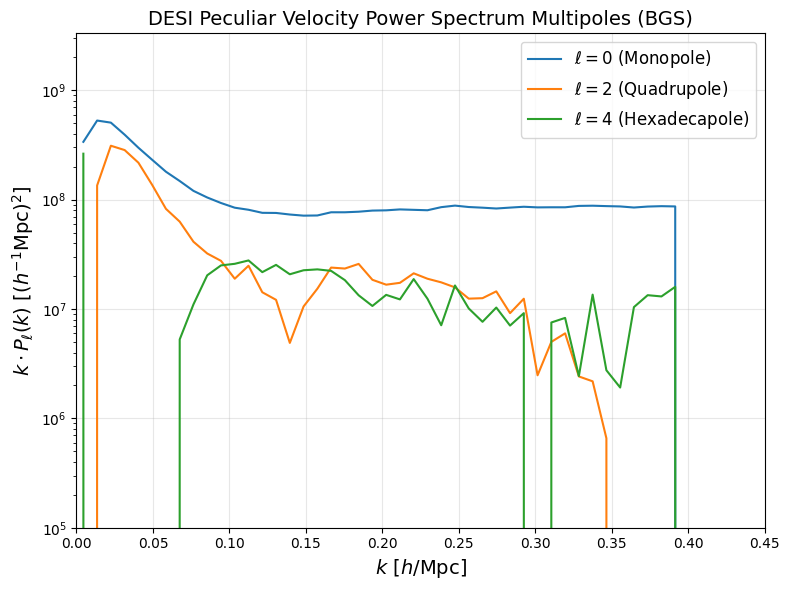

In [9]:
plt.figure(figsize=(8, 6))
plt.plot(k_mom, k_mom*P0, label=r'$\ell=0$'+' (Monopole)')
plt.plot(k_mom, k_mom*P2, label=r'$\ell=2$'+' (Quadrupole)')
plt.plot(k_mom, k_mom*P4, label=r'$\ell=4$'+' (Hexadecapole)')
# Add a horizontal zero-line for reference (useful for P2 and P4)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

# Formatting the plot
plt.xlim(0, 0.45)  # Restricting to standard cosmological fitting ranges
plt.xlabel(r'$k \ [h/\mathrm{Mpc}]$', fontsize=14)
plt.ylabel(r'$k \cdot P_\ell(k) \ [(h^{-1}\mathrm{Mpc})^2]$', fontsize=14)
plt.title('DESI Peculiar Velocity Power Spectrum Multipoles (BGS)', fontsize=14)
#plt.xscale('log')
plt.yscale('log')
plt.ylim(bottom=1e5)

plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

# Display the plot
plt.show()

In [6]:
pk = np.zeros((45, 10))
for i in range(675):
    pv = np.loadtxt('/global/cfs/cdirs/desicollab/science/td/pv/PS/Y1/Data/Prod/FP/Mock_mom%s'%i)
    pk = pk + pv

pk = pk/675

In [8]:
k_mom = pk[:,1]
P0 = pk[:,2]
P2 = pk[:,4]
P4 = pk[:,6]

In [10]:
np.save('/pscratch/sd/l/lgong/pv_cov/pvk_desiy1_mock_output.npy', pk)